In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, average_precision_score
from sklearn.inspection import permutation_importance

# Load the dataset
df = pd.read_csv("water_potability.csv")
print("Data shape:", df.shape)
df.head()

Data shape: (3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


Missing values % per column:
ph                 14.99
Hardness            0.00
Solids              0.00
Chloramines         0.00
Sulfate            23.84
Conductivity        0.00
Organic_carbon      0.00
Trihalomethanes     4.95
Turbidity           0.00
Potability          0.00
dtype: float64


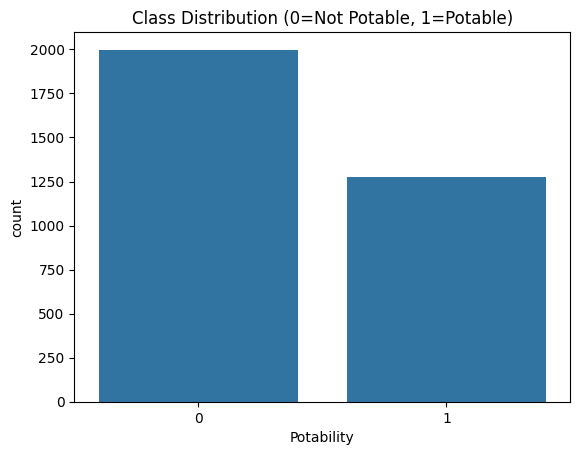

In [8]:
# Print missing value percentages
print("Missing values % per column:")
print((df.isna().mean() * 100).round(2))

# Plot Class Distribution
sns.countplot(x="Potability", data=df)
plt.title("Class Distribution (0=Not Potable, 1=Potable)")
plt.show()

In [9]:
# Separate features and target
X = df.drop(columns=["Potability"])
y = df["Potability"]

# Split into 80% train and 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Build baseline evaluation pipelines with balanced class weights
lr_balanced = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=42))
])

svm_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
    ("model", SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=42))
])

# Train and print baseline results
for name, model in [("Logistic Regression", lr_balanced), ("SVM (RBF)", svm_pipe)]:
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    print(f"=== {name} ===")
    print(classification_report(y_test, preds, digits=4))

=== Logistic Regression ===
              precision    recall  f1-score   support

           0     0.6186    0.4500    0.5210       400
           1     0.3973    0.5664    0.4670       256

    accuracy                         0.4954       656
   macro avg     0.5079    0.5082    0.4940       656
weighted avg     0.5322    0.4954    0.4999       656

=== SVM (RBF) ===
              precision    recall  f1-score   support

           0     0.6816    0.6850    0.6833       400
           1     0.5039    0.5000    0.5020       256

    accuracy                         0.6128       656
   macro avg     0.5928    0.5925    0.5926       656
weighted avg     0.6123    0.6128    0.6125       656



In [10]:
# Set up Random Forest grid search pipeline
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("model", RandomForestClassifier(random_state=42, class_weight="balanced", n_jobs=-1))
])

# Optimized search space for local execution speed
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10, 20, None],
    "model__min_samples_leaf": [2, 4]
}

grid_rf = GridSearchCV(
    rf_pipeline, param_grid=param_grid, scoring="average_precision", cv=5, n_jobs=-1, verbose=1
)

print("Starting Local Grid Search...")
grid_rf.fit(X_train, y_train)

print("\nBest PR-AUC Found:", grid_rf.best_score_)
print("Best Params:", grid_rf.best_params_)

# Set up best_rf for the final analysis cell
best_rf = grid_rf.best_estimator_

Starting Local Grid Search...
Fitting 5 folds for each of 12 candidates, totalling 60 fits

Best PR-AUC Found: 0.5893373244201899
Best Params: {'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}


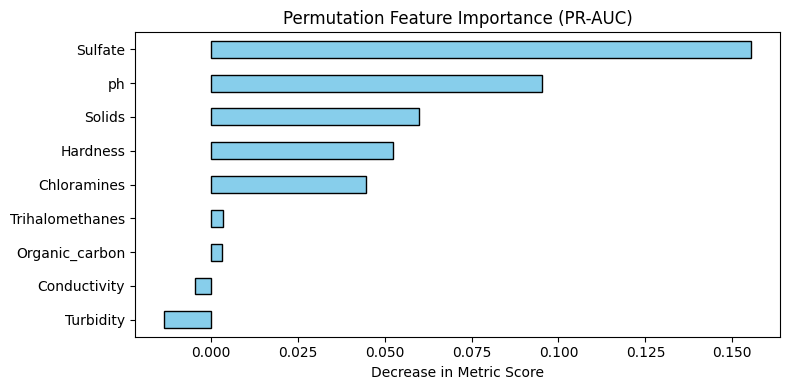

In [11]:
# Compute feature importance based on the tuned model
result = permutation_importance(
    best_rf, X_test, y_test, n_repeats=15, random_state=42, scoring="average_precision"
)

imp = pd.Series(result.importances_mean, index=X.columns).sort_values(ascending=True)

# Plot the graph
plt.figure(figsize=(8,4))
imp.plot(kind="barh", color='skyblue', edgecolor='black')
plt.title("Permutation Feature Importance (PR-AUC)")
plt.xlabel("Decrease in Metric Score")
plt.tight_layout()
plt.show()

In [12]:
from sklearn.metrics import classification_report, average_precision_score, accuracy_score

rf_preds = best_rf.predict(X_test)
rf_proba = best_rf.predict_proba(X_test)[:, 1]

print("=== Random Forest (Tuned) ===")
print(classification_report(y_test, rf_preds, digits=4))

print(f"accuracy                         {accuracy_score(y_test, rf_preds):.4f}        {len(y_test)}")
print(f"PR-AUC Score (CV Best)           {grid_rf.best_score_:.4f}")
print(f"PR-AUC Score (Test Set)          {average_precision_score(y_test, rf_proba):.4f}")

=== Random Forest (Tuned) ===
              precision    recall  f1-score   support

           0     0.6718    0.8750    0.7600       400
           1     0.6296    0.3320    0.4348       256

    accuracy                         0.6631       656
   macro avg     0.6507    0.6035    0.5974       656
weighted avg     0.6553    0.6631    0.6331       656

accuracy                         0.6631        656
PR-AUC Score (CV Best)           0.5893
PR-AUC Score (Test Set)          0.6017


<Figure size 1000x800 with 0 Axes>

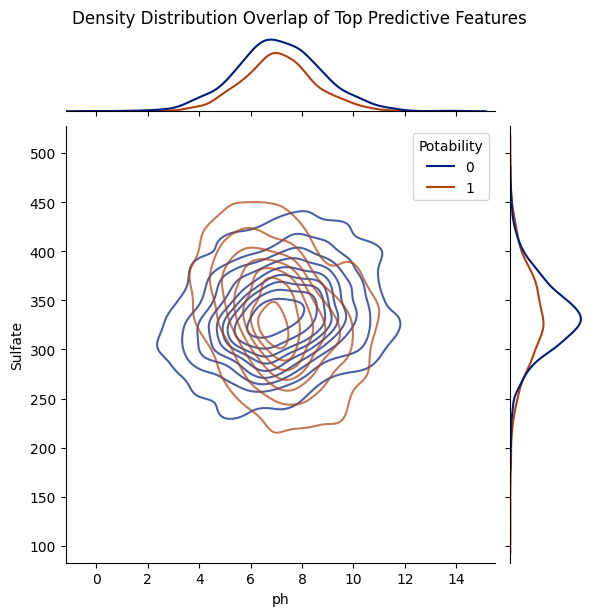

In [13]:
# Advanced Bonus Visualization: Joint Distribution of the top 2 features (Sulfate vs pH)
plt.figure(figsize=(10, 8))
sns.jointplot(
    data=df, 
    x="ph", 
    y="Sulfate", 
    hue="Potability", 
    kind="kde", # Kernel Density Estimate shows concentration rings like a topographical map
    palette="dark", 
    alpha=0.7
)
plt.suptitle("Density Distribution Overlap of Top Predictive Features", y=1.02)
plt.savefig('advanced_density_map.png', bbox_inches='tight')
plt.show()